In [2]:
import os
for dp, dn, fn in os.walk("/kaggle/input"):
    if dp[len("/kaggle/input"):].count(os.sep) <= 3:
        print(dp, "| files:", len(fn))

/kaggle/input | files: 0
/kaggle/input/notebooks | files: 0
/kaggle/input/notebooks/haruistaken | files: 0
/kaggle/input/notebooks/haruistaken/phase3-alt | files: 4
/kaggle/input/notebooks/risha8750 | files: 0
/kaggle/input/notebooks/risha8750/phase-1b | files: 4
/kaggle/input/notebooks/risha8750/phase-6a | files: 4
/kaggle/input/notebooks/risha8750/major-project-phase-2a-cache | files: 6
/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer | files: 4
/kaggle/input/datasets | files: 0
/kaggle/input/datasets/risha8750 | files: 0
/kaggle/input/datasets/risha8750/phase2-core3 | files: 1
/kaggle/input/datasets/risha8750/phase2-latest-outputs | files: 0


In [3]:
import os, glob
def sig(root):
    return sorted((os.path.relpath(os.path.join(dp,f),root), os.path.getsize(os.path.join(dp,f)))
                  for dp,_,fs in os.walk(root) for f in fs)
roots=sorted(glob.glob("/kaggle/input/*/*phase2_core*")+glob.glob("/kaggle/input/phase2_core*"))
print(roots)
if len(roots)>1:
    base=sig(roots[0])
    for r in roots[1:]: print(r,"identical to first:",sig(r)==base)
print(sig(roots[0])[:30] if roots else "no phase2_core dir found")

[]
no phase2_core dir found


In [4]:
import subprocess
print(subprocess.run("grep -n '^def \\|^class ' $(find /kaggle/input -name phase2_core.py | head -1)",shell=True,capture_output=True,text=True).stdout)

22:def seed_everything(seed=42):
31:def file_key(name):
37:def archive_inventory(root):
46:def choose_archives(table):
60:def read_id_list(path):
96:def find_split_manifest(root):
175:def member_map(zf,suffix):
183:def read_xyz(zf,name):
194:def read_wireframe(zf,name):
211:def sample_points(raw,count,rng):
217:def normalize_sample(raw,corners,count,rng):
243:def build_cache(source_root,cache_root,point_count=2048,max_corners=64,max_edges=128,shard_size=256,seed=42):
299:class RoofDataset(Dataset):
341:def square_distance(src,dst):
345:def index_points(points,idx):
350:def farthest_point_sample(xyz,npoint):
365:def query_neighbors(radius,nsample,xyz,new_xyz):
374:class SetAbstraction(nn.Module):
400:class FeaturePropagation(nn.Module):
422:class CornerPointNet2(nn.Module):
448:def corner_targets(points,corners,counts,scales,radius_m=0.35):
463:def focal_binary(logits,targets,alpha=0.75,gamma=2.0):
471:def corner_loss(logits,offsets,pred_offsets,labels):
478:def predict_corners(points,l

In [5]:
import os, glob
for root in ["/kaggle/input/notebooks/haruistaken/phase3-alt",
             "/kaggle/input/notebooks/risha8750/phase-1b",
             "/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer",
             "/kaggle/input/datasets/risha8750/phase2-core3"]:
    print("\n##", root)
    for dp,_,fs in os.walk(root):
        for f in sorted(fs):
            p=os.path.join(dp,f); print(f"{os.path.getsize(p):>12,}  {p}")

print("\n## checkpoints anywhere:")
print(glob.glob("/kaggle/input/**/*.pt",recursive=True))

core=glob.glob("/kaggle/input/**/phase2_core.py",recursive=True)[0]
L=open(core).read().splitlines()
for a,b in [(211,242),(422,447),(478,536)]:
    print(f"\n--- lines {a}-{b} ---"); print("\n".join(L[a-1:b]))


## /kaggle/input/notebooks/haruistaken/phase3-alt
   1,249,861  /kaggle/input/notebooks/haruistaken/phase3-alt/__notebook__.ipynb
      26,061  /kaggle/input/notebooks/haruistaken/phase3-alt/__output__.json
     611,302  /kaggle/input/notebooks/haruistaken/phase3-alt/__results__.html
           0  /kaggle/input/notebooks/haruistaken/phase3-alt/custom.css
     159,394  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___20_2.png
      51,885  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___22_2.png
      23,713  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___23_1.png
      22,859  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___23_3.png
      18,690  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___23_5.png
      19,296  /kaggle/input/notebooks/haruistaken/phase3-alt/__results___files/__results___23_7.png
      31,702  /kaggle/input/notebooks/haru

In [6]:
import sys, glob, inspect, json, torch, pandas as pd
P2="/kaggle/input/datasets/risha8750/phase2-core3"
sys.path.insert(0,P2)
import phase2_core as pc

for n in ["normalize_sample","sample_points","predict_corners","interpolate_features","match_corners","reconstruction_counts"]:
    print("\n#####",n); print(inspect.getsource(getattr(pc,n)))
for cls in [pc.CornerPointNet2, pc.EdgeGraphNet]:
    print("\n#####",cls.__name__); print(inspect.getsource(cls))

cks=sorted(glob.glob("/kaggle/input/datasets/risha8750/phase2-latest-outputs/**/*.pt",recursive=True))
print("\ncheckpoints:",cks)
for p in cks:
    if p.endswith("best.pt"):
        c=torch.load(p,map_location="cpu",weights_only=False)
        print(p, type(c), list(c.keys())[:8] if isinstance(c,dict) else "")

B3="/kaggle/input/notebooks/haruistaken/phase3-alt/phase3_uncertainty"
print("\nphase3 cols:",list(pd.read_csv(f"{B3}/phase3_results.csv",nrows=0).columns))
B4="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/phase4_decision"
print("phase4 cols:",list(pd.read_csv(f"{B4}/phase4_decisions.csv",nrows=0).columns))
print(open(f"{B4}/policy_config.json").read())

nb=json.load(open("/kaggle/input/notebooks/haruistaken/phase3-alt/__notebook__.ipynb"))
for i,c in enumerate(nb["cells"]):
    s="".join(c["source"]) if c["cell_type"]=="code" else ""
    if "N_PASSES" in s or "def " in s and ("uncert" in s.lower() or "mc_dropout" in s.lower() or "corner_conf" in s.lower()):
        print(f"\n#### phase3 cell {i}\n",s[:3500])


##### normalize_sample
def normalize_sample(raw,corners,count,rng):
    xyz=raw[:,:3]
    joined=np.vstack([xyz,corners])
    low=joined.min(0)
    high=joined.max(0)
    center=(low+high)/2
    scale=np.linalg.norm(joined-center,axis=1).max()
    scale=max(float(scale),1e-6)
    chosen=sample_points(raw,count,rng)
    xyz_norm=(chosen[:,:3]-center)/scale
    attrs=chosen[:,3:8]
    if attrs.shape[1]<5:
        attrs=np.pad(attrs,((0,0),(0,5-attrs.shape[1])))
    attrs=attrs.astype(np.float64)
    if attrs.shape[1]>=3:
        rgb=attrs[:,:3]
        attrs[:,:3]=np.clip(rgb/(255 if np.nanmax(rgb)>1.5 else 1),0,1)
    for col in range(3,5):
        lo=np.percentile(attrs[:,col],1)
        hi=np.percentile(attrs[:,col],99)
        attrs[:,col]=np.clip((attrs[:,col]-lo)/(hi-lo+1e-8),0,1)
    points=np.concatenate([xyz_norm,attrs],1).astype(np.float32)
    corner_norm=((corners-center)/scale).astype(np.float32)
    return points,corner_norm,center.astype(np.float64),scale


##### sample_p

In [7]:
import sys, glob, json, hashlib, time, numpy as np, pandas as pd, torch
from pathlib import Path
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN
sys.path.insert(0,"/kaggle/input/datasets/risha8750/phase2-core3")
import phase2_core as pc

CITY_DIR=Path("/kaggle/input/notebooks/risha8750/phase-6a/phase6_city3d")
OUT_DIR6=Path("/kaggle/working/phase6_scores"); OUT_DIR6.mkdir(exist_ok=True)
CK="/kaggle/input/datasets/risha8750/phase2-latest-outputs/phase2_outputs"
SCORE_THRESH=0.7; N_PASSES=8; JITTER_STD_M=0.05; DROP_FRACTION=0.08
MATCH_TOL=1.0; TOLS=(0.5,1.0); N_POINTS=2048
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:",DEVICE)

idx=pd.read_csv(CITY_DIR/"city3d_index.csv",dtype={"building_id":str})
SH=CITY_DIR/"shards"; assert SH.exists() and len(idx)>0
print("rows:",len(idx),"| shards:",len(list(SH.glob("*.pt"))))

corner_model=pc.CornerPointNet2().to(DEVICE); edge_model=pc.EdgeGraphNet().to(DEVICE)
cc=torch.load(f"{CK}/corner/corner_best.pt",map_location=DEVICE,weights_only=False)
ec=torch.load(f"{CK}/edge/edge_best.pt",map_location=DEVICE,weights_only=False)
print(corner_model.load_state_dict(cc["model"]), edge_model.load_state_dict(ec["model"]))
corner_model.eval(); edge_model.eval()
for p in list(corner_model.parameters())+list(edge_model.parameters()): p.requires_grad=False
print("corner epoch",cc["epoch"],"| edge epoch",ec["epoch"])
print("edge last history:",ec["history"][-1] if ec["history"] else None)

device: cpu
rows: 18933 | shards: 74
<All keys matched successfully> <All keys matched successfully>
corner epoch 19 | edge epoch 7
edge last history: {'epoch': 7, 'train_loss': 0.0167485819844415, 'val_loss': 0.016266808015138662, 'lr': 8.511087728614862e-05}


In [8]:
_cur={"i":None,"d":None}
def get_shard(i):
    if _cur["i"]!=i: _cur["i"]=i; _cur["d"]=torch.load(SH/f"shard_{i:04d}.pt",weights_only=False)
    return _cur["d"]

def load_item(r,rng):
    d=get_shard(int(r.shard))[int(r.row)]
    c=np.array([r.cx,r.cy,r.cz],dtype=np.float64); sc=float(r.scale)
    raw=d["points"].astype(np.float64)*sc+c
    truth_m=d["corners"][:d["n_corners"]].astype(np.float64)*sc+c
    pts,_,center,scale=pc.normalize_sample(raw,truth_m,N_POINTS,rng)
    return dict(points=torch.from_numpy(pts),center=center,scale=scale,
                truth_m=truth_m,truth_edges=d["edges"][:d["n_edges"]])

denorm=lambda p,c,s: np.asarray(p)*s+c

def perturb_points(points,jitter_std_norm,drop_fraction,rng):
    points=points.clone(); n=points.shape[0]
    n_drop=int(n*drop_fraction)
    if n_drop>0:
        keep=rng.choice(n,n-n_drop,replace=False); refill=rng.choice(keep,n_drop,replace=True)
        points=points[np.concatenate([keep,refill])]
    if jitter_std_norm>0: points[:,:3]+=torch.randn_like(points[:,:3])*jitter_std_norm
    return points

def multi_pass_corners(item,rng):
    scale=float(item["scale"]); center=item["center"]; j=JITTER_STD_M/scale; passes=[]
    with torch.no_grad():
        for p in range(N_PASSES):
            pts=item["points"] if p==0 else perturb_points(item["points"],j,DROP_FRACTION,rng)
            pts=pts.unsqueeze(0).to(DEVICE)
            logits,offsets,shared=corner_model(pts)
            pn,ps=pc.predict_corners(pts[0],logits[0],offsets[0],scale,score_thresh=SCORE_THRESH)
            passes.append({"pred_norm":pn,"pred_scores":ps,"pred_m":denorm(pn,center,scale),
                           "shared":shared[0].cpu() if p==0 else None})
    return passes

def corner_uncertainty(passes,tol=MATCH_TOL):
    ref=passes[0]["pred_m"]; n=len(ref)
    if n==0: return {"n_ref_corners":0,"mean_corner_spread_m":np.nan,"max_corner_spread_m":np.nan,"mean_existence_rate":np.nan,"corner_confidence":0.0}
    samples=[[] for _ in range(n)]; exist=np.zeros(n)
    for p in passes:
        m,_,_=pc.match_corners(ref,p["pred_m"],tol)
        for a,b in m.items(): samples[a].append(p["pred_m"][b]); exist[a]+=1
    stds=[float(np.std(np.array(s),axis=0).mean()) for s in samples if len(s)>=2]
    ms=float(np.mean(stds)) if stds else 0.0; mx=float(np.max(stds)) if stds else 0.0
    me=float((exist/len(passes)).mean())
    return {"n_ref_corners":n,"mean_corner_spread_m":ms,"max_corner_spread_m":mx,"mean_existence_rate":me,"corner_confidence":float(np.exp(-ms/0.5)*me)}

def entropy(p):
    p=np.clip(p,1e-6,1-1e-6); return -(p*np.log2(p)+(1-p)*np.log2(1-p))

def edge_uncertainty(ref_pass,points):
    pn,ps,shared=ref_pass["pred_norm"],ref_pass["pred_scores"],ref_pass["shared"]
    if len(pn)<2:
        return {"mean_edge_entropy":np.nan,"edge_predictive_entropy":np.nan,"edge_epistemic_uncertainty":np.nan,"predicted_positive_rate":np.nan,"edge_confidence":0.0},np.zeros((0,2),dtype=int)
    cx=torch.as_tensor(pn,dtype=torch.float32,device=DEVICE); cs=torch.as_tensor(ps,dtype=torch.float32,device=DEVICE)
    feat=pc.interpolate_features(points.to(DEVICE),shared.to(DEVICE),pn)
    edge_model.train(); probs=[]
    with torch.no_grad():
        for _ in range(N_PASSES):
            pairs,lg=edge_model(cx,cs,feat); probs.append(torch.sigmoid(lg).cpu().numpy())
    edge_model.eval()
    probs=np.stack(probs); mp=probs.mean(0)
    pe=entropy(mp); mi=np.clip(pe-entropy(probs).mean(0),0,None)
    pos=mp>=0.5; sel=pe[pos] if pos.any() else pe
    ec_=float(np.clip(0.7*(1-pe.mean())+0.3*(1-mi.mean()),0,1))
    return {"mean_edge_entropy":float(sel.mean()) if len(sel) else np.nan,"edge_predictive_entropy":float(pe.mean()),
            "edge_epistemic_uncertainty":float(mi.mean()),"predicted_positive_rate":float(pos.mean()),"edge_confidence":ec_},pairs.cpu().numpy()[pos]

def conf_class(x): return "high" if x>0.85 else ("moderate" if x>=0.60 else "low")
def f1(tp,pr,tr): return 0.0 if pr+tr==0 else 2*tp/(pr+tr)

def score_row(r):
    rng=np.random.default_rng(int.from_bytes(hashlib.sha256(r.building_id.encode()).digest()[:4],"little"))
    item=load_item(r,rng); passes=multi_pass_corners(item,rng)
    cu=corner_uncertainty(passes); eu,pred_edges=edge_uncertainty(passes[0],item["points"])
    mc=float(0.5*cu["corner_confidence"]+0.5*eu["edge_confidence"])
    out={"building_id":r.building_id,"subset":r.subset,"coverage_class":r.coverage_class,"in_model_scope":bool(r.in_model_scope),
         "num_points":N_POINTS,"num_predicted_corners":cu["n_ref_corners"],"num_predicted_edges":len(pred_edges),
         **cu,**eu,"model_confidence":mc,"combined_confidence":mc,"confidence_class":conf_class(mc)}
    for tol in TOLS:
        a=pc.reconstruction_counts(passes[0]["pred_m"],pred_edges,item["truth_m"],item["truth_edges"],tolerance_m=tol)
        t=f"{tol:g}m"
        out[f"corner_f1_{t}"]=f1(a["corner_tp"],a["corner_pred"],a["corner_true"])
        out[f"edge_f1_{t}"]=f1(a["edge_tp"],a["edge_pred"],a["edge_true"])
        out[f"min_f1_{t}"]=min(out[f"corner_f1_{t}"],out[f"edge_f1_{t}"])
    out["actual_corner_tp"]=a["corner_tp"]; out["actual_corner_true"]=a["corner_true"]
    return out

In [9]:
sub=idx[idx.in_model_scope].sample(5,random_state=0)
t0=time.time(); rows=[score_row(r) for r in sub.itertuples(index=False)]
print(f"{(time.time()-t0)/5:.2f} s/building")
print(pd.DataFrame(rows)[["building_id","subset","num_predicted_corners","num_predicted_edges","corner_confidence","edge_confidence","model_confidence","min_f1_0.5m","min_f1_1m"]].round(3))

1.74 s/building
  building_id subset  num_predicted_corners  num_predicted_edges  \
0  ahn3_12571   AHN3                      4                    6   
1  ahn3_01345   AHN3                      4                    6   
2  ahn3_00177   AHN3                      4                    6   
3  ahn3_02023   AHN3                      4                    6   
4  ahn3_05369   AHN3                      4                    6   

   corner_confidence  edge_confidence  model_confidence  min_f1_0.5m  \
0              0.599            0.830             0.714        0.000   
1              0.173            0.741             0.457        0.000   
2              0.474            0.992             0.733        0.077   
3              0.699            0.990             0.844        0.050   
4              0.241            0.977             0.609        0.000   

   min_f1_1m  
0      0.000  
1      0.048  
2      0.077  
3      0.050  
4      0.000  


In [10]:
RUN="in_scope"
LIMIT=500
OUT_CSV=OUT_DIR6/f"city3d_scores_{RUN}.csv"
todo=idx[idx.in_model_scope] if RUN=="in_scope" else idx
if OUT_CSV.exists():
    done=pd.read_csv(OUT_CSV,dtype={"building_id":str}); rows=done.to_dict("records"); seen=set(done.building_id)
else: rows=[]; seen=set()
todo=todo[~todo.building_id.isin(seen)]
if LIMIT: todo=todo.head(LIMIT)
print(len(todo),"to score,",len(seen),"done")
for n,r in enumerate(todo.itertuples(index=False),1):
    try: rows.append(score_row(r))
    except Exception as e: rows.append({"building_id":r.building_id,"subset":r.subset,"error":str(e)})
    if n%200==0: pd.DataFrame(rows).to_csv(OUT_CSV,index=False); print(n,"/",len(todo))
pd.DataFrame(rows).to_csv(OUT_CSV,index=False)
res=pd.DataFrame(rows); print(res.get("error",pd.Series(dtype=object)).notna().sum(),"errors")
print(res.groupby("subset")[["model_confidence","min_f1_0.5m","min_f1_1m"]].describe().round(3).T)

500 to score, 0 done
200 / 500
400 / 500
0 errors
subset                     AHN3
model_confidence count  500.000
                 mean     0.589
                 std      0.150
                 min      0.208
                 25%      0.504
                 50%      0.557
                 75%      0.679
                 max      0.962
min_f1_0.5m      count  500.000
                 mean     0.017
                 std      0.026
                 min      0.000
                 25%      0.000
                 50%      0.000
                 75%      0.039
                 max      0.143
min_f1_1m        count  500.000
                 mean     0.026
                 std      0.028
                 min      0.000
                 25%      0.000
                 50%      0.032
                 75%      0.048
                 max      0.143


In [11]:
import json, glob
base="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer"
cands=glob.glob(f"{base}/**/*.ipynb",recursive=True)
print(cands)
path=[c for c in cands if "__notebook__" in c] or cands
nb=json.load(open(path[0]))
for i,c in enumerate(nb["cells"]):
    s="".join(c["source"]) if c["cell_type"]=="code" else ""
    if "model_confidence_before" in s or "def apply_policy" in s or "t_acc" in s:
        print(f"\n#### phase4 cell {i}\n",s[:3500])

['/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/__notebook__.ipynb']

#### phase4 cell 6
 d['is_bad']=(d.min_f1<0.5).astype(int)
tune=d[d.split=='train'].reset_index(drop=True)
hold=d[d.split.isin(['val','test'])].reset_index(drop=True)

def decide(df,c,r=0):
    mc=df.model_confidence.values; iou=df.ext_iou.values; av=~np.isnan(iou)
    dis=av&(iou<c['iou_lo'])
    hi=mc>=c['t_acc']; lo=mc<c['t_low']; can=r<c['max_retry']
    conds=[hi&~dis,hi&dis,lo&can,lo,dis,av]
    acts=['ACCEPT','ESCALATE','RETRY','ESCALATE','ESCALATE','SUPPLEMENT']
    why=['HIGH_CONF','EXTERNAL_DISAGREE','LOW_MODEL_CONF','RETRY_FAILED' if r>0 else 'LOW_MODEL_CONF','EXTERNAL_DISAGREE','MID_CONF_EXT_OK']
    a=np.select(conds,acts,default=c['mid_no_ext'])
    w=np.select(conds,why,default='MID_CONF_NO_EXT')
    return a,w

cfg0=dict(t_acc=0.85,t_low=0.60,iou_lo=0.70,mid_no_ext='ACCEPT_FLAG',max_retry=1)
edge=pd.DataFrame({'model_confidence':[0.85,0.8499,0.60,0.5999,0.0,0.9,0.7,0.7,0.7,0.9],
 'e

In [12]:
import glob
print("working:", glob.glob("/kaggle/working/**/city3d_index.csv", recursive=True))
print("input:  ", glob.glob("/kaggle/input/**/city3d_index.csv", recursive=True))

working: []
input:   ['/kaggle/input/notebooks/risha8750/phase-6a/phase6_city3d/city3d_index.csv']


In [14]:
import pandas as pd
P3a="/kaggle/input/notebooks/haruistaken/phase3-alt/phase3_uncertainty/phase3_results.csv"
P4="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/phase4_decision/phase4_decisions.csv"
a=pd.read_csv(P3a,dtype={"building_id":str}); d4=pd.read_csv(P4,dtype={"building_id":str})
m=a.merge(d4[["building_id","model_confidence_before"]],on="building_id")
diff=float((m["model_confidence"]-m["model_confidence_before"]).abs().max())
print("n:",len(m),"| max abs diff:",round(diff,6))

n: 3207 | max abs diff: 0.47192


In [15]:
import numpy as np, pandas as pd, glob
P3a="/kaggle/input/notebooks/haruistaken/phase3-alt/phase3_uncertainty/phase3_results.csv"
P4="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/phase4_decision/phase4_decisions.csv"
a=pd.read_csv(P3a,dtype={"building_id":str}); d4=pd.read_csv(P4,dtype={"building_id":str})
m=a.merge(d4,on="building_id",suffixes=("_a","_4"))
diff=(m["model_confidence"]-m["model_confidence_before"]).abs()
print("diff quantiles:",diff.quantile([.5,.9,.99,1]).round(4).to_dict(),"| share >0.01:",round(float((diff>0.01).mean()),3))
print("corr(before, phase3-alt cols):")
for c in ["model_confidence","combined_confidence","corner_confidence","edge_confidence"]:
    print(f"  {c:20s} corr {m[c].corr(m['model_confidence_before']):.4f}  mean {m[c].mean():.3f}")
print("mean before:",round(float(m.model_confidence_before.mean()),3))
for name,col in [("phase3-alt model_confidence","model_confidence"),("phase4 before","model_confidence_before")]:
    v=m[col]; print(f"{name:28s} >=0.65: {(v>=0.65).mean():.3f} | <0.633: {(v<0.633).mean():.3f}")
print("phase4 action shares:",d4.action_final.value_counts(normalize=True).round(3).to_dict())
P3b=glob.glob("/kaggle/input/**/phase3-results-csv/phase3_results.csv",recursive=True); print("phase3-results-csv found:",P3b)
if P3b:
    b=pd.read_csv(P3b[0],dtype={"building_id":str}).merge(d4[["building_id","model_confidence_before"]],on="building_id")
    print("phase3-results-csv vs before max diff:",round(float((b.model_confidence-b.model_confidence_before).abs().max()),6))

diff quantiles: {0.5: 0.0983, 0.9: 0.2009, 0.99: 0.3314, 1.0: 0.4719} | share >0.01: 0.951
corr(before, phase3-alt cols):
  model_confidence     corr 0.5074  mean 0.764
  combined_confidence  corr 0.3175  mean 0.717
  corner_confidence    corr 0.4434  mean 0.718
  edge_confidence      corr 0.4306  mean 0.809
mean before: 0.677
phase3-alt model_confidence  >=0.65: 0.896 | <0.633: 0.070
phase4 before                >=0.65: 0.614 | <0.633: 0.300
phase4 action shares: {'ACCEPT': 0.614, 'ESCALATE': 0.3, 'ACCEPT_FLAG': 0.086}
phase3-results-csv found: []


In [17]:
import glob, pandas as pd
P3b=glob.glob("/kaggle/input/**/phase3-results-csv/*",recursive=True); print(P3b)
P4="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/phase4_decision/phase4_decisions.csv"
d4=pd.read_csv(P4,dtype={"building_id":str})
b=pd.read_csv([p for p in P3b if p.endswith("phase3_results.csv")][0],dtype={"building_id":str})
print(list(b.columns))
m=b.merge(d4[["building_id","model_confidence_before"]],on="building_id")
print("n",len(m),"| max diff vs before:",round(float((m.model_confidence-m.model_confidence_before).abs().max()),6))
print("mean model_confidence:",round(float(b.model_confidence.mean()),3),"| >=0.65:",round(float((b.model_confidence>=0.65).mean()),3))

['/kaggle/input/datasets/risha8750/phase3-results-csv/phase3_results.csv']
['building_id', 'coverage_class', 'num_points', 'num_predicted_corners', 'num_predicted_edges', 'n_ref_corners', 'mean_corner_spread_m', 'max_corner_spread_m', 'mean_existence_rate', 'corner_confidence', 'mean_edge_entropy', 'edge_predictive_entropy', 'edge_epistemic_uncertainty', 'predicted_positive_rate', 'edge_confidence', 'model_confidence', 'osm_available', 'osm_status', 'osm_centroid_distance_m', 'osm_iou', 'osm_area_error', 'microsoft_available', 'microsoft_status', 'microsoft_centroid_distance_m', 'microsoft_iou', 'microsoft_area_error', 'external_confidence', 'combined_confidence', 'confidence_class', 'actual_corner_tp', 'actual_corner_pred', 'actual_corner_true', 'actual_edge_tp', 'actual_edge_pred', 'actual_edge_true']
n 3207 | max diff vs before: 0.47192
mean model_confidence: 0.764 | >=0.65: 0.896


In [18]:
import sys, glob, json, hashlib, time, numpy as np, pandas as pd, torch
from pathlib import Path
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN
sys.path.insert(0,"/kaggle/input/datasets/risha8750/phase2-core3")
import phase2_core as pc

CITY_DIR=Path("/kaggle/input/notebooks/risha8750/phase-6a/phase6_city3d")
OUT_DIR6=Path("/kaggle/working/phase6_scores"); OUT_DIR6.mkdir(exist_ok=True)
CK="/kaggle/input/datasets/risha8750/phase2-latest-outputs/phase2_outputs"
P3A="/kaggle/input/notebooks/haruistaken/phase3-alt/phase3_uncertainty/phase3_results.csv"
P4="/kaggle/input/notebooks/risha8750/phase-4-agentic-decision-layer/phase4_decision/phase4_decisions.csv"
SCORE_THRESH=0.7; N_PASSES=8; JITTER_STD_M=0.05; DROP_FRACTION=0.08
TOLS=(0.5,1.0); N_POINTS=2048
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:",DEVICE)

idx=pd.read_csv(CITY_DIR/"city3d_index.csv",dtype={"building_id":str})
if "coverage_class" not in idx: idx["coverage_class"]=np.where(idx.density_pts_m2>=idx.density_pts_m2.median(),"dense","sparse")
SH=CITY_DIR/"shards"; assert SH.exists() and len(idx)>0
print("rows:",len(idx),"| shards:",len(list(SH.glob("*.pt"))))

corner_model=pc.CornerPointNet2().to(DEVICE); edge_model=pc.EdgeGraphNet().to(DEVICE)
cc=torch.load(f"{CK}/corner/corner_best.pt",map_location=DEVICE,weights_only=False)
ec=torch.load(f"{CK}/edge/edge_best.pt",map_location=DEVICE,weights_only=False)
print(corner_model.load_state_dict(cc["model"],strict=False), edge_model.load_state_dict(ec["model"],strict=False))
corner_model.eval(); edge_model.eval()
for p in list(corner_model.parameters())+list(edge_model.parameters()): p.requires_grad=False
print("corner epoch",cc["epoch"],"| edge epoch",ec["epoch"])

device: cpu
rows: 18933 | shards: 74
<All keys matched successfully> <All keys matched successfully>
corner epoch 19 | edge epoch 7


In [19]:
_cur={"i":None,"d":None}
def get_shard(i):
    if _cur["i"]!=i: _cur["i"]=i; _cur["d"]=torch.load(SH/f"shard_{i:04d}.pt",weights_only=False)
    return _cur["d"]
denorm=lambda p,c,s: np.asarray(p)*s+c

def load_item(r,rng):
    d=get_shard(int(r.shard))[int(r.row)]
    c=np.array([r.cx,r.cy,r.cz],dtype=np.float64); sc=float(r.scale)
    raw=d["points"].astype(np.float64)*sc+c
    truth_m=d["corners"][:d["n_corners"]].astype(np.float64)*sc+c
    pts,_,center,scale=pc.normalize_sample(raw,truth_m,N_POINTS,rng)
    return dict(points=torch.from_numpy(pts),center=center,scale=scale,truth_m=truth_m,truth_edges=d["edges"][:d["n_edges"]])

def perturb_points(points,jitter_std_norm,drop_fraction,rng):
    points=points.clone(); n=points.shape[0]; nd=int(n*drop_fraction)
    if nd>0:
        keep=rng.choice(n,n-nd,replace=False); refill=rng.choice(keep,nd,replace=True)
        points=points[np.concatenate([keep,refill])]
    if jitter_std_norm>0: points[:,:3]+=torch.randn_like(points[:,:3])*jitter_std_norm
    return points

OFFSET_NORM_M=0.35
def p3_predict_corners(points,logits,offsets,scale,score_thresh=0.5,offset_norm_m=OFFSET_NORM_M,cluster_m=0.25,min_samples=1,max_corners=64):
    scores=torch.sigmoid(logits).detach().cpu().numpy()
    xyz=points[:,:3].detach().cpu().numpy(); delta=offsets.detach().cpu().numpy()
    keep=np.flatnonzero(scores>=score_thresh)
    empty=(np.zeros((0,3),np.float32),np.zeros((0,),np.float32))
    if len(keep)==0: return empty
    prop=xyz[keep]+delta[keep]*offset_norm_m/float(scale)
    groups=DBSCAN(eps=cluster_m/float(scale),min_samples=min_samples).fit_predict(prop)
    cs,cf=[],[]
    for g in sorted(set(groups)):
        if g<0: continue
        mk=groups==g; w=scores[keep][mk]
        cs.append(np.average(prop[mk],axis=0,weights=w+1e-6)); cf.append(float(w.max()))
    if not cs: return empty
    o=np.argsort(cf)[::-1][:max_corners]
    return np.asarray(cs,np.float32)[o],np.asarray(cf,np.float32)[o]

def multi_pass_corners(item,rng):
    scale=float(item["scale"]); center=item["center"]; j=JITTER_STD_M/scale; passes=[]
    with torch.no_grad():
        for p in range(N_PASSES):
            pts=item["points"] if p==0 else perturb_points(item["points"],j,DROP_FRACTION,rng)
            pts=pts.unsqueeze(0).to(DEVICE)
            lg,off,sh=corner_model(pts)
            pn,ps=p3_predict_corners(pts[0],lg[0],off[0],scale,score_thresh=SCORE_THRESH)
            passes.append({"pred_norm":pn,"pred_scores":ps,"pred_m":denorm(pn,center,scale),"shared":sh[0].cpu() if p==0 else None})
    return passes

def corner_uncertainty(passes,tol=1.0):
    ref=passes[0]["pred_m"]; n=len(ref)
    if n==0: return {"n_ref_corners":0,"mean_corner_spread_m":np.nan,"max_corner_spread_m":np.nan,"mean_existence_rate":np.nan,"corner_confidence":0.0}
    samples=[[] for _ in range(n)]; exist=np.zeros(n)
    for p in passes:
        m,_,_=pc.match_corners(ref,p["pred_m"],tol)
        for a,b in m.items(): samples[a].append(p["pred_m"][b]); exist[a]+=1
    stds=[float(np.std(np.array(s),axis=0).mean()) for s in samples if len(s)>=2]
    ms=float(np.mean(stds)) if stds else 0.0; mx=float(np.max(stds)) if stds else 0.0; me=float((exist/len(passes)).mean())
    return {"n_ref_corners":n,"mean_corner_spread_m":ms,"max_corner_spread_m":mx,"mean_existence_rate":me,"corner_confidence":float(np.exp(-ms/0.5)*me)}

def entropy(p):
    p=np.clip(p,1e-6,1-1e-6); return -(p*np.log2(p)+(1-p)*np.log2(1-p))

def edge_uncertainty(ref_pass,points):
    pn,ps,shared=ref_pass["pred_norm"],ref_pass["pred_scores"],ref_pass["shared"]
    if len(pn)<2:
        return {"mean_edge_entropy":np.nan,"edge_predictive_entropy":np.nan,"edge_epistemic_uncertainty":np.nan,"predicted_positive_rate":np.nan,"edge_confidence":0.0},np.zeros((0,2),dtype=int)
    cx=torch.as_tensor(pn,dtype=torch.float32,device=DEVICE); cs=torch.as_tensor(ps,dtype=torch.float32,device=DEVICE)
    feat=pc.interpolate_features(points.to(DEVICE),shared.to(DEVICE),pn)
    edge_model.train(); probs=[]
    with torch.no_grad():
        for _ in range(N_PASSES):
            pairs,lg=edge_model(cx,cs,feat); probs.append(torch.sigmoid(lg).cpu().numpy())
    edge_model.eval()
    probs=np.stack(probs); mp=probs.mean(0); pe=entropy(mp); mi=np.clip(pe-entropy(probs).mean(0),0,None)
    pos=mp>=0.5; sel=pe[pos] if pos.any() else pe
    ec_=float(np.clip(0.7*(1-pe.mean())+0.3*(1-mi.mean()),0,1))
    return {"mean_edge_entropy":float(sel.mean()) if len(sel) else np.nan,"edge_predictive_entropy":float(pe.mean()),
            "edge_epistemic_uncertainty":float(mi.mean()),"predicted_positive_rate":float(pos.mean()),"edge_confidence":ec_},pairs.cpu().numpy()[pos]

def conf_class(x): return "high" if x>0.85 else ("moderate" if x>=0.60 else "low")
def f1(tp,pr,tr): return 0.0 if pr+tr==0 else 2*tp/(pr+tr)

def score_item(item,bid,meta):
    rng=np.random.default_rng(int.from_bytes(hashlib.sha256(bid.encode()).digest()[:4],"little"))
    passes=multi_pass_corners(item,rng); cu=corner_uncertainty(passes); eu,pred_edges=edge_uncertainty(passes[0],item["points"])
    mc=float(0.5*cu["corner_confidence"]+0.5*eu["edge_confidence"])
    out={"building_id":bid,**meta,"num_predicted_corners":cu["n_ref_corners"],"num_predicted_edges":len(pred_edges),
         **cu,**eu,"model_confidence":mc,"combined_confidence":mc,"confidence_class":conf_class(mc)}
    for tol in TOLS:
        a=pc.reconstruction_counts(passes[0]["pred_m"],pred_edges,item["truth_m"],item["truth_edges"],tolerance_m=tol); t=f"{tol:g}m"
        out[f"corner_f1_{t}"]=f1(a["corner_tp"],a["corner_pred"],a["corner_true"]); out[f"edge_f1_{t}"]=f1(a["edge_tp"],a["edge_pred"],a["edge_true"])
        out[f"min_f1_{t}"]=min(out[f"corner_f1_{t}"],out[f"edge_f1_{t}"])
    return out

def score_row(r):
    item=load_item(r,np.random.default_rng(0))
    return score_item(item,r.building_id,{"subset":r.subset,"coverage_class":r.coverage_class,"in_model_scope":bool(r.in_model_scope)})
print("functions ready")

functions ready


In [20]:
sub=idx[idx.in_model_scope].sample(5,random_state=0)
t0=time.time(); rows=[score_row(r) for r in sub.itertuples(index=False)]
print(f"{(time.time()-t0)/5:.2f} s/building -> est. {(time.time()-t0)/5*8488/60:.0f} min for 8,488")
print(pd.DataFrame(rows)[["building_id","subset","num_predicted_corners","num_predicted_edges","corner_confidence","edge_confidence","model_confidence","min_f1_0.5m","min_f1_1m"]].round(3))

1.33 s/building -> est. 189 min for 8,488
  building_id subset  num_predicted_corners  num_predicted_edges  \
0  ahn3_12571   AHN3                      0                    0   
1  ahn3_01345   AHN3                      0                    0   
2  ahn3_00177   AHN3                      0                    0   
3  ahn3_02023   AHN3                      2                    1   
4  ahn3_05369   AHN3                      0                    0   

   corner_confidence  edge_confidence  model_confidence  min_f1_0.5m  \
0              0.000            0.000             0.000        0.000   
1              0.000            0.000             0.000        0.000   
2              0.000            0.000             0.000        0.000   
3              0.536            0.876             0.706        0.057   
4              0.000            0.000             0.000        0.000   

   min_f1_1m  
0      0.000  
1      0.000  
2      0.000  
3      0.057  
4      0.000  


In [21]:
P2C=Path("/kaggle/input/notebooks/risha8750/major-project-phase-2a-cache/phase2_cache")
assert P2C.exists(), "attach notebook risha8750/major-project-phase-2a-cache as an input"
tidx=pd.read_csv(P2C/"index.csv",dtype={"building_id":str}); tidx=tidx[tidx.split=="test"]
ref=pd.read_csv(P3A,dtype={"building_id":str}).set_index("building_id")
samp=tidx[tidx.building_id.isin(ref.index)].sample(100,random_state=0)
tcache={}
def tallinn_item(r):
    if r.shard not in tcache:
        if len(tcache)>3: tcache.clear()
        tcache[r.shard]=torch.load(P2C/r.shard,map_location="cpu",weights_only=False)
    it=tcache[r.shard][int(r.row)]; c=it["center"].numpy().astype(np.float64); s=float(it["scale"])
    nc,ne=int(it["corner_count"]),int(it["edge_count"])
    return dict(points=it["points"],center=c,scale=s,truth_m=denorm(it["corners"][:nc].numpy(),c,s),truth_edges=it["edges"][:ne].numpy())
rows=[score_item(tallinn_item(r),r.building_id,{"subset":"tallinn"}) for r in samp.itertuples(index=False)]
v=pd.DataFrame(rows).set_index("building_id").join(ref,rsuffix="_ref")
for c in ["model_confidence","corner_confidence","edge_confidence"]:
    print(f"{c:18s} corr {v[c].corr(v[c+'_ref']):.3f} | mean abs diff {float((v[c]-v[c+'_ref']).abs().mean()):.3f}")
print("same predicted-corner count:",round(float((v.num_predicted_corners==v.num_predicted_corners_ref).mean()),3))

model_confidence   corr 0.324 | mean abs diff 0.322
corner_confidence  corr 0.149 | mean abs diff 0.275
edge_confidence    corr 0.284 | mean abs diff 0.484
same predicted-corner count: 0.02


In [22]:
d4=pd.read_csv(P4,dtype={"building_id":str})[["building_id","half"]]
a=pd.read_csv(P3A,dtype={"building_id":str}).merge(d4,on="building_id")
def f1v(tp,p,t): tp,p,t=[np.asarray(x,float) for x in (tp,p,t)]; return np.where(p+t>0,2*tp/np.maximum(p+t,1),0.0)
a["min_f1"]=np.minimum(f1v(a.actual_corner_tp,a.actual_corner_pred,a.actual_corner_true),f1v(a.actual_edge_tp,a.actual_edge_pred,a.actual_edge_true))
THR=0.3265306122448979; a["is_bad"]=(a.min_f1<=THR).astype(int)
tune,hold=a[a.half=="tune"],a[a.half=="hold"]
T_LOW=float(tune.model_confidence.quantile(0.300)); T_ACC=float(tune.model_confidence.quantile(1-0.614))
json.dump({"t_low":T_LOW,"t_acc":T_ACC,"label_thr":THR},open(OUT_DIR6/"rebased_thresholds.json","w"))
print("t_low",round(T_LOW,4),"t_acc",round(T_ACC,4),"| overall bad rate",round(float(a.is_bad.mean()),3),"| tune",len(tune),"hold",len(hold))
act=np.where(hold.model_confidence>=T_ACC,"ACCEPT",np.where(hold.model_confidence<T_LOW,"ESCALATE","ACCEPT_FLAG"))
acc=pd.Series(act,index=hold.index).isin(["ACCEPT","ACCEPT_FLAG"])
print("HOLD review",round(float((act=="ESCALATE").mean()),3),"| accepted bad",round(float(hold.is_bad[acc].mean()),3),"| accept-all bad",round(float(hold.is_bad.mean()),3))

t_low 0.7165 t_acc 0.7393 | overall bad rate 0.185 | tune 1603 hold 1604
HOLD review 0.295 | accepted bad 0.102 | accept-all bad 0.18


In [23]:
RUN="in_scope"        # later: "all" for the out-of-scope stress set
LIMIT=500             # trial first; set to None for the full run
OUT_CSV=OUT_DIR6/f"city3d_scores_{RUN}.csv"
todo=idx[idx.in_model_scope] if RUN=="in_scope" else idx
if OUT_CSV.exists():
    done=pd.read_csv(OUT_CSV,dtype={"building_id":str}); rows=done.to_dict("records"); seen=set(done.building_id)
else: rows=[]; seen=set()
todo=todo[~todo.building_id.isin(seen)]
if LIMIT: todo=todo.head(LIMIT)
print(len(todo),"to score,",len(seen),"done")
for n,r in enumerate(todo.itertuples(index=False),1):
    try: rows.append(score_row(r))
    except Exception as e: rows.append({"building_id":r.building_id,"subset":r.subset,"error":str(e)})
    if n%200==0: pd.DataFrame(rows).to_csv(OUT_CSV,index=False); print(n,"/",len(todo))
pd.DataFrame(rows).to_csv(OUT_CSV,index=False)
res=pd.DataFrame(rows); print("errors:",int(res["error"].notna().sum()) if "error" in res else 0)

500 to score, 500 done
200 / 500
400 / 500
errors: 0


In [25]:
from sklearn.metrics import roc_auc_score
th=json.load(open(OUT_DIR6/"rebased_thresholds.json")); T_LOW,T_ACC,THR=th["t_low"],th["t_acc"],th["label_thr"]
S=pd.read_csv(OUT_DIR6/"city3d_scores_in_scope.csv",dtype={"building_id":str})
if "error" in S: S=S[S["error"].isna()]
S["action"]=np.where(S.model_confidence>=T_ACC,"ACCEPT",np.where(S.model_confidence<T_LOW,"ESCALATE","ACCEPT_FLAG"))
S["is_bad"]=(S["min_f1_1m"]<=THR).astype(int); acc=S.action.isin(["ACCEPT","ACCEPT_FLAG"])
print(S.groupby("subset").agg(n=("building_id","size"),conf=("model_confidence","mean"),bad=("is_bad","mean")).round(3))
print(pd.crosstab(S.subset,S.action,normalize="index").round(3))
print("review",round(float((S.action=="ESCALATE").mean()),3),"| accepted bad",round(float(S.is_bad[acc].mean()),3),
      "| bad caught",round(float(((S.action=="ESCALATE")&(S.is_bad==1)).sum()/max(S.is_bad.sum(),1)),3))
print("AUC:",round(roc_auc_score(S.is_bad,1-S.model_confidence),3) if S.is_bad.nunique()>1 else "one class only")
S.to_csv(OUT_DIR6/"city3d_scores_with_actions.csv",index=False)

           n   conf  bad
subset                  
AHN3    1000  0.314  1.0
action  ACCEPT  ACCEPT_FLAG  ESCALATE
subset                               
AHN3     0.096        0.014      0.89
review 0.89 | accepted bad 1.0 | bad caught 0.89
AUC: one class only


                         mean   25%   50%     75%     max
corner_f1_0.5m          0.041   0.0   0.0   0.039   0.375
corner_f1_1m            0.061   0.0   0.0   0.143   0.375
edge_f1_1m              0.013   0.0   0.0   0.032   0.143
min_f1_1m               0.013   0.0   0.0   0.032   0.143
num_predicted_corners   2.060   0.0   3.5   4.000   4.000
n_corners              41.511  39.0  40.0  49.000  64.000
num_predicted_edges     3.003   0.0   3.0   6.000   6.000
n_edges                36.456  32.0  36.0  45.000  63.000
predicted 0 corners: 0.454 | corner_f1_1m>0.5: 0.0 | edge_f1_1m>0.5: 0.0
spearman(model_confidence, min_f1_1m) = 0.59
spearman(model_confidence, corner_f1_1m) = 0.74
spearman(model_confidence, edge_f1_1m) = 0.59


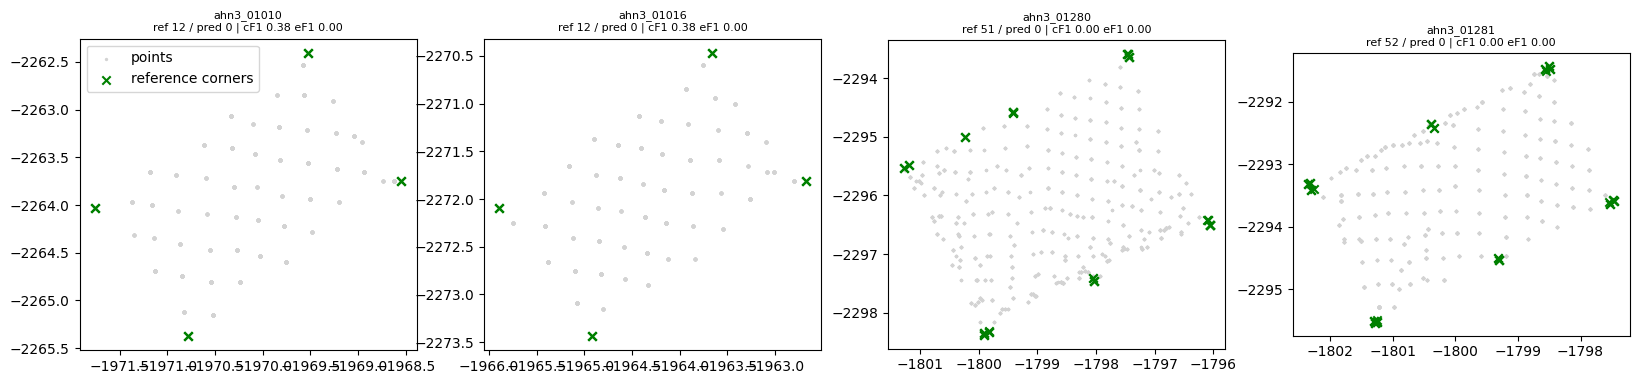

In [26]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
D=S.merge(idx[["building_id","n_corners","n_edges","raw_points","scale"]],on="building_id",suffixes=("","_ref"))
cols=["corner_f1_0.5m","corner_f1_1m","edge_f1_1m","min_f1_1m","num_predicted_corners","n_corners","num_predicted_edges","n_edges"]
print(D[cols].describe().round(3).T[["mean","25%","50%","75%","max"]])
print("predicted 0 corners:",round(float((D.num_predicted_corners==0).mean()),3),
      "| corner_f1_1m>0.5:",round(float((D["corner_f1_1m"]>0.5).mean()),3),
      "| edge_f1_1m>0.5:",round(float((D["edge_f1_1m"]>0.5).mean()),3))
for c in ["min_f1_1m","corner_f1_1m","edge_f1_1m"]:
    print(f"spearman(model_confidence, {c}) =",round(float(spearmanr(D.model_confidence,D[c])[0]),3))

pick=D.sort_values("corner_f1_1m",ascending=False).iloc[[0,1,len(D)//2,len(D)//2+1]]
fig,axs=plt.subplots(1,4,figsize=(20,5))
for ax,(_,x) in zip(axs,pick.iterrows()):
    r=idx[idx.building_id==x.building_id].iloc[0]
    item=load_item(r,np.random.default_rng(0)); passes=multi_pass_corners(item,np.random.default_rng(0))
    xy=item["points"][:,:2].numpy()*item["scale"]+item["center"][:2]
    ax.scatter(xy[:,0],xy[:,1],s=2,c="lightgray",label="points")
    t=item["truth_m"]; ax.scatter(t[:,0],t[:,1],marker="x",c="green",label="reference corners")
    p=passes[0]["pred_m"]
    if len(p): ax.scatter(p[:,0],p[:,1],marker="o",facecolors="none",edgecolors="red",label="predicted")
    ax.set_aspect("equal"); ax.set_title(f"{x.building_id}\nref {len(t)} / pred {len(p)} | cF1 {x['corner_f1_1m']:.2f} eF1 {x['edge_f1_1m']:.2f}",fontsize=8)
axs[0].legend(); plt.show()

In [27]:
print(idx.groupby("subset").raw_points.describe().round(0)[["count","25%","50%","75%","max"]])
Msub=idx[(idx.in_model_scope)&(idx.n_corners.between(6,24))&(idx.raw_points>=300)]
print("matched-complexity buildings:",len(Msub),Msub.groupby("subset").size().to_dict())
samp=pd.concat([g.sample(min(len(g),60),random_state=0) for _,g in Msub.groupby("subset")]) if len(Msub) else Msub
out=[]
for th in [0.3,0.5,0.7]:
    SCORE_THRESH=th
    R=pd.DataFrame([score_row(r) for r in samp.itertuples(index=False)])
    R=R.merge(idx[["building_id","n_corners"]],on="building_id")
    out.append(dict(thresh=th,n=len(R),pred_corners=R.num_predicted_corners.mean(),ref_corners=R.n_corners.mean(),
        corner_f1=R["corner_f1_1m"].mean(),edge_f1=R["edge_f1_1m"].mean(),share_cf1_gt_0_5=(R["corner_f1_1m"]>0.5).mean(),
        zero_pred=(R.num_predicted_corners==0).mean(),conf=R.model_confidence.mean()))
SCORE_THRESH=0.7
print(pd.DataFrame(out).round(3).to_string(index=False))

             count    25%     50%     75%       max
subset                                             
AHN3       18729.0  155.0   602.0  1068.0  122039.0
Dales3d      153.0  529.0  1707.0  8372.0   17064.0
Vaihingen     51.0  186.0   478.0  1788.0    6407.0
matched-complexity buildings: 168 {'AHN3': 168}
 thresh  n  pred_corners  ref_corners  corner_f1  edge_f1  share_cf1_gt_0_5  zero_pred  conf
    0.3 60        24.750       16.867      0.381    0.148              0.25       0.00 0.566
    0.5 60         4.817       16.867      0.328    0.215              0.00       0.00 0.729
    0.7 60         1.217       16.867      0.127    0.038              0.00       0.25 0.457


1. RECONSTRUCTION ACCURACY (held-out half, 1.0 m tolerance)
              n  corner_precision  corner_recall  corner_f1  edge_precision  \
all     1604.0             0.733          0.767      0.749           0.346   
dense    817.0             0.743          0.781      0.762           0.361   
sparse   787.0             0.725          0.756      0.740           0.335   

        edge_recall  edge_f1  mean_min_f1  bad_rate  
all           0.536    0.420        0.575     0.180  
dense         0.551    0.436        0.612     0.175  
sparse        0.525    0.409        0.537     0.186  

2. CALIBRATION
       conf  corner_recall  min_f1  bad_rate    n
bin                                             
0    0.597          0.773   0.365     0.491  161
1    0.672          0.801   0.431     0.356  160
2    0.704          0.805   0.484     0.256  160
3    0.730          0.774   0.465     0.236  161
4    0.752          0.799   0.519     0.144  160
5    0.773          0.818   0.560     0.112  160
6

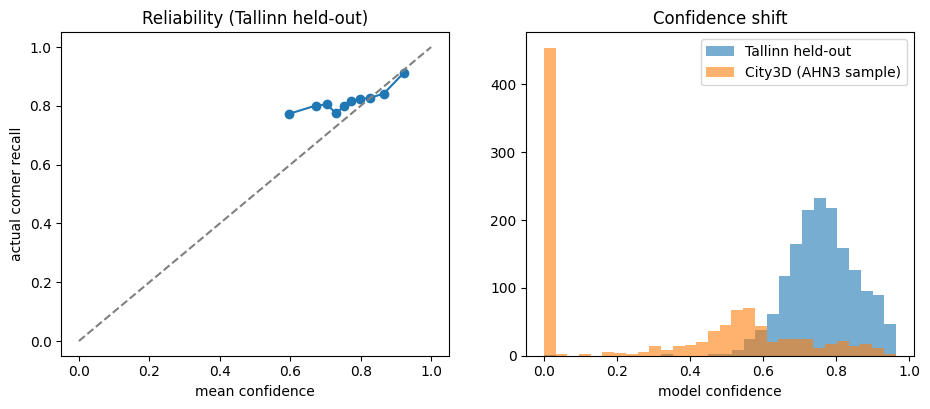

saved to /kaggle/working/phase6_eval


In [28]:
import glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
EV=Path("/kaggle/working/phase6_eval"); EV.mkdir(exist_ok=True)
THR=0.3265306122448979

def f1v(tp,p,t): tp,p,t=[np.asarray(x,float) for x in (tp,p,t)]; return np.where(p+t>0,2*tp/np.maximum(p+t,1),0.0)
a=pd.read_csv(P3A,dtype={"building_id":str}).merge(pd.read_csv(P4,dtype={"building_id":str})[["building_id","half"]],on="building_id")
a["corner_f1"]=f1v(a.actual_corner_tp,a.actual_corner_pred,a.actual_corner_true)
a["edge_f1"]=f1v(a.actual_edge_tp,a.actual_edge_pred,a.actual_edge_true)
a["min_f1"]=np.minimum(a.corner_f1,a.edge_f1); a["is_bad"]=(a.min_f1<=THR).astype(int)
a["corner_recall"]=a.actual_corner_tp/a.actual_corner_true.clip(lower=1)
tune=a[a.half=="tune"]; hold=a[a.half=="hold"].copy()
T_LOW=float(tune.model_confidence.quantile(0.30)); T_ACC=float(tune.model_confidence.quantile(1-0.614))
hold["action"]=np.where(hold.model_confidence>=T_ACC,"ACCEPT",np.where(hold.model_confidence<T_LOW,"ESCALATE","ACCEPT_FLAG"))

def agg(df):
    ctp,cp,ct=df.actual_corner_tp.sum(),df.actual_corner_pred.sum(),df.actual_corner_true.sum()
    etp,ep,et=df.actual_edge_tp.sum(),df.actual_edge_pred.sum(),df.actual_edge_true.sum()
    return pd.Series(dict(n=len(df),corner_precision=ctp/cp,corner_recall=ctp/ct,corner_f1=2*ctp/(cp+ct),
        edge_precision=etp/ep,edge_recall=etp/et,edge_f1=2*etp/(ep+et),mean_min_f1=df.min_f1.mean(),bad_rate=df.is_bad.mean()))
acc_tab=pd.concat([agg(hold).rename("all")]+[agg(g).rename(k) for k,g in hold.groupby("coverage_class")],axis=1).T
print("1. RECONSTRUCTION ACCURACY (held-out half, 1.0 m tolerance)\n",acc_tab.round(3))

hold["bin"]=pd.qcut(hold.model_confidence.rank(method="first"),10,labels=False)
rel=hold.groupby("bin").agg(conf=("model_confidence","mean"),corner_recall=("corner_recall","mean"),min_f1=("min_f1","mean"),bad_rate=("is_bad","mean"),n=("is_bad","size"))
cal=dict(spearman_conf_minf1=float(spearmanr(hold.model_confidence,hold.min_f1)[0]),
         spearman_conf_cornerrecall=float(spearmanr(hold.model_confidence,hold.corner_recall)[0]),
         auc_low_conf_predicts_bad=float(roc_auc_score(hold.is_bad,1-hold.model_confidence)),
         ece_conf_vs_cornerrecall=float((rel.n*(rel.conf-rel.corner_recall).abs()).sum()/rel.n.sum()))
print("\n2. CALIBRATION\n",rel.round(3),"\n",{k:round(v,3) for k,v in cal.items()})

def pol(esc,y):
    acc=~esc; return dict(review_rate=esc.mean(),accepted_bad_rate=y[acc].mean() if acc.any() else np.nan,
        bad_caught=(esc&(y==1)).sum()/max(y.sum(),1),good_escalated=(esc&(y==0)).sum()/max((y==0).sum(),1),
        cost=(np.where(acc,2.0*y,0.0)+np.where(esc,1.0,0.0)).mean())
y=hold.is_bad.values; esc=(hold.action=="ESCALATE").values
tau=np.quantile(hold.model_confidence,esc.mean())
pol_tab=pd.DataFrame({"accept_all":pol(np.zeros(len(y),bool),y),"rebased_rule":pol(esc,y),
                      "single_threshold":pol((hold.model_confidence<tau).values,y),"oracle":pol(y==1,y)}).T
print("\n3. CORRECTION / TRIAGE POLICY (held-out, no retry)\n",pol_tab.round(3))

sysr=dict(n_scored=len(a),zero_predicted_corners=float((a.num_predicted_corners==0).mean()),
          osm_available=float(a.osm_available.mean()),microsoft_available=float(a.microsoft_available.mean()))
print("\n4. SYSTEM RELIABILITY\n",{k:round(v,3) for k,v in sysr.items()})

solar=None; c5=glob.glob("/kaggle/input/**/phase5_building_solar.csv",recursive=True)
if c5:
    s5=pd.read_csv(c5[0],dtype={"building_id":str})[["building_id","annual_kwh"]]
    h=hold.merge(s5,on="building_id",how="left"); h["annual_kwh"]=h.annual_kwh.fillna(0); tot=h.annual_kwh.sum()
    accd=h.action.isin(["ACCEPT","ACCEPT_FLAG"])
    solar=dict(yield_in_bad_if_accept_all=float(h.annual_kwh[h.is_bad==1].sum()/tot),yield_in_accepted_bad_rule=float(h.annual_kwh[accd&(h.is_bad==1)].sum()/tot))
    print("\n5. SOLAR YIELD AT RISK (held-out)",{k:round(v,3) for k,v in solar.items()})
else: print("\n5. solar skipped (attach a Phase 5 output containing phase5_building_solar.csv to include it)")

S=pd.read_csv(OUT_DIR6/"city3d_scores_in_scope.csv",dtype={"building_id":str})
if "error" in S: S=S[S["error"].isna()]
S["escalate"]=S.model_confidence<T_LOW
city=S.groupby("subset").agg(n=("building_id","size"),mean_conf=("model_confidence","mean"),zero_pred=("num_predicted_corners",lambda x:(x==0).mean()),
    escalated=("escalate","mean"),corner_f1=("corner_f1_1m","mean"),edge_f1=("edge_f1_1m","mean"))
print("\n6. CITY3D ROBUSTNESS (in-scope AHN3 sample; reference is an algorithm-generated mesh)\n",city.round(3))

fig,ax=plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(rel.conf,rel.corner_recall,"o-"); ax[0].plot([0,1],[0,1],"--",c="gray"); ax[0].set_xlabel("mean confidence"); ax[0].set_ylabel("actual corner recall"); ax[0].set_title("Reliability (Tallinn held-out)")
ax[1].hist(hold.model_confidence,bins=30,alpha=.6,label="Tallinn held-out"); ax[1].hist(S.model_confidence,bins=30,alpha=.6,label="City3D (AHN3 sample)"); ax[1].legend(); ax[1].set_title("Confidence shift"); ax[1].set_xlabel("model confidence")
plt.savefig(EV/"phase6_overview.png",dpi=160,bbox_inches="tight"); plt.show()

acc_tab.to_csv(EV/"accuracy.csv"); rel.to_csv(EV/"reliability.csv"); pol_tab.to_csv(EV/"policy.csv"); city.to_csv(EV/"city3d_robustness.csv")
json.dump(dict(thresholds=dict(t_low=T_LOW,t_acc=T_ACC,label_thr=THR),calibration=cal,system=sysr,solar=solar),open(EV/"phase6_summary.json","w"),indent=2)
print("saved to",EV)